# Proyecto 2 y 3 — Fase A: Análisis Exploratorio
## Siniestralidad vial en Santiago de Cali (2016–2024)

**Pregunta de negocio:** ¿qué factores de tiempo, tipo de vehículo y tipo de accidente se asocian a que un siniestro vial en Cali termine **con víctimas** (lesionados o fallecidos)? La respuesta sirve para focalizar operativos de control y campañas de prevención de la Secretaría de Movilidad.

Este notebook continúa con el mismo dataset del Proyecto 1. Aquí solo se hace una **preparación mínima** para poder explorar (tipos de dato y gravedad estandarizada); la limpieza formal (nulos, outliers, encoding, escalado) queda para la Fase B.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_style("whitegrid")

# Ruta del CSV (en la raíz del repositorio) y carpeta para guardar las gráficas
RUTA_CSV = Path("../../siniestralidad_2016_2024.csv")
RUTA_GRAFICAS = Path("graficas")
RUTA_GRAFICAS.mkdir(exist_ok=True)

if not RUTA_CSV.exists():
    raise FileNotFoundError(f"No se encontró el archivo fuente: {RUTA_CSV.resolve()}")

## 1. Carga del dataset

In [2]:
df_raw = pd.read_csv(
    RUTA_CSV,
    sep=";",
    encoding="latin-1",
    dtype="string",
    na_values=[".", ""],
    low_memory=False,
)

print(f"Registros: {len(df_raw):,} | Columnas: {df_raw.shape[1]}")
display(df_raw.head())
df_raw.info()

Registros: 371,003 | Columnas: 10


,Código,Fecha,Tipo confirmado,Dirección reporte,Tipo clase de accidente,Tipo clase de accidente.1,Tipo confirmado.1,Medio de reporte,Numero vehículos,Tipo de vehículos implicados
0,96159,1/01/2016,Solo daños,Carrera 56 Con Calle 1 A,<NA>,<NA>,Solo Da?os,RADIO,2,MOTOCICLETA
1,96160,1/01/2016,Negativo,Calle 72 O Con Carrera 28 H,<NA>,<NA>,Negativo,RADIO,<NA>,<NA>
2,96161,1/01/2016,Con lesionado,Carrera 94 Con Calle 4 C,ATROPELLO,ATROPELLO,Por Atropello,TELEF?NICO 127,2,MOTOCICLETA
3,96162,1/01/2016,Con lesionado,Carrera 8 A Con Calle 44,VOLCAMIENTO,VOLCAMIENTO,Por Volcamiento,RADIO,1,MOTOCICLETA
4,96163,1/01/2016,Negativo,Carrera 28 H Con Calle 72 M,<NA>,<NA>,Negativo,TELEF?NICO 127,<NA>,<NA>


<class 'pandas.DataFrame'>
RangeIndex: 371003 entries, 0 to 371002
Data columns (total 10 columns):
 #   Column                        Non-Null Count   Dtype 
---  ------                        --------------   ----- 
 0   Código                        371002 non-null  string
 1   Fecha                         371002 non-null  string
 2   Tipo confirmado               371000 non-null  string
 3   Dirección reporte             187317 non-null  string
 4   Tipo clase de accidente       45745 non-null   string
 5   Tipo clase de accidente.1     45745 non-null   string
 6   Tipo confirmado.1             347614 non-null  string
 7   Medio de reporte              82904 non-null   string
 8   Numero vehículos              176579 non-null  string
 9   Tipo de vehículos implicados  148789 non-null  string
dtypes: string(10)
memory usage: 49.7 MB


Todas las columnas llegan como texto y el carácter `.` se usa como marcador de "sin dato", por eso se lee como nulo. Hay dos pares de columnas repetidas (`Tipo clase de accidente` y `Tipo confirmado`), igual que en el Proyecto 1.

## 2. Preparación mínima para explorar

In [3]:
df = df_raw.rename(columns={
    "Código": "id_siniestro",
    "Fecha": "fecha",
    "Tipo confirmado": "tipo_confirmado",
    "Dirección reporte": "direccion_reporte",
    "Tipo clase de accidente": "tipo_accidente",
    "Tipo clase de accidente.1": "tipo_accidente_dup",
    "Tipo confirmado.1": "detalle_confirmado",
    "Medio de reporte": "medio_reporte",
    "Numero vehículos": "numero_vehiculos",
    "Tipo de vehículos implicados": "tipos_vehiculos",
})

df["fecha"] = pd.to_datetime(df["fecha"], format="%d/%m/%Y", errors="coerce")
df["numero_vehiculos"] = pd.to_numeric(df["numero_vehiculos"].str.replace(".", "", regex=False), errors="coerce")

# Gravedad estandarizada (mismo criterio del Proyecto 1)
texto = df["tipo_confirmado"].str.upper().fillna("")
df["gravedad"] = np.select(
    [texto.str.contains("FALLEC"), texto.str.contains("LESION"),
     texto.str.contains("SOLO DA"), texto.str.contains("NEGATIV")],
    ["Con fallecido", "Con lesionado", "Solo daños", "Negativo"],
    default="Sin dato",
)

In [4]:
# Variables derivadas que se usarán en la exploración
df["anio"] = df["fecha"].dt.year
df["mes"] = df["fecha"].dt.month
df["dia_semana"] = df["fecha"].dt.dayofweek          # 0 = lunes
df["tipo_accidente"] = df["tipo_accidente"].str.upper().str.replace("?", "I", regex=False)

# Indicadores 0/1 por siniestro
df["involucra_moto"] = df["tipos_vehiculos"].str.contains("MOTO").fillna(False).astype(int)
df["es_lesionado"] = (df["gravedad"] == "Con lesionado").astype(int)
df["es_fallecido"] = (df["gravedad"] == "Con fallecido").astype(int)
df["es_solo_danos"] = (df["gravedad"] == "Solo daños").astype(int)
df["con_victimas"] = df["es_lesionado"] + df["es_fallecido"]

DIAS = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
ORDEN_GRAVEDAD = ["Negativo", "Solo daños", "Con lesionado", "Con fallecido"]

display(df["gravedad"].value_counts())
print("Rango de fechas:", df["fecha"].min().date(), "a", df["fecha"].max().date())

gravedad
Negativo         246110
Solo daños        74030
Con lesionado     47500
Con fallecido      3360
Sin dato              3
Name: count, dtype: int64

Rango de fechas: 2016-01-01 a 2024-11-02


In [5]:
# Proporción de registros por gravedad
resumen = (df["gravedad"].value_counts(normalize=True) * 100).round(1)
display(resumen.reindex(ORDEN_GRAVEDAD).to_frame("% de registros"))

# Los reportes "Negativo" no corresponden a siniestros confirmados.
# El análisis de negocio se hace sobre los siniestros confirmados.
confirmados = df[df["gravedad"].isin(ORDEN_GRAVEDAD[1:])].copy()
print(f"Siniestros confirmados: {len(confirmados):,} ({len(confirmados) / len(df):.1%} del total)")

,% de registros
gravedad,
Negativo,66.3
Solo daños,20.0
Con lesionado,12.8
Con fallecido,0.9


Siniestros confirmados: 124,890 (33.7% del total)


**Insight:** dos de cada tres reportes (66%) que recibe la central terminan como "Negativo", es decir, la unidad llega y no encuentra un siniestro que atender. Eso es una carga operativa grande que no aparece en las estadísticas de accidentalidad. Los 124.890 siniestros confirmados son la base del análisis de negocio.

## 3. Calidad de los datos: completitud por año

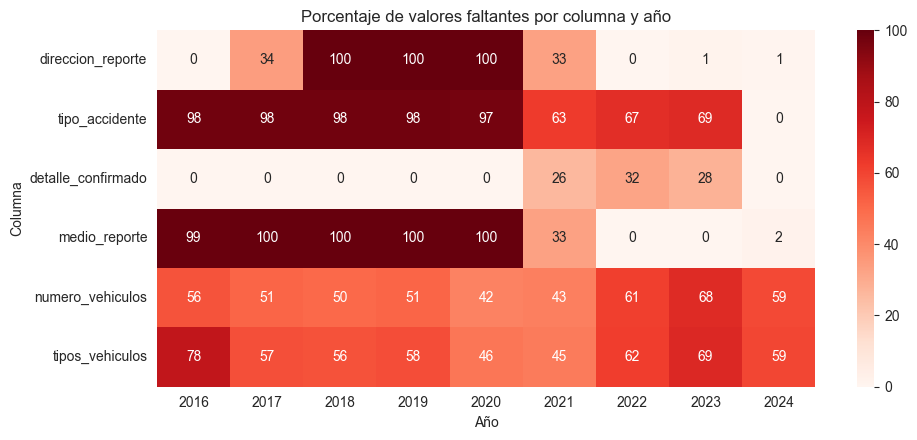

In [6]:
columnas_revisar = ["direccion_reporte", "tipo_accidente", "detalle_confirmado",
                    "medio_reporte", "numero_vehiculos", "tipos_vehiculos"]

# % de nulos de cada columna, calculado año por año
nulos_anio = df[columnas_revisar].isna().groupby(df["anio"]).mean() * 100
nulos_anio.index = nulos_anio.index.astype(int)

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.heatmap(nulos_anio.T, annot=True, fmt=".0f", cmap="Reds", ax=ax)
ax.set_title("Porcentaje de valores faltantes por columna y año")
ax.set_xlabel("Año")
ax.set_ylabel("Columna")
plt.tight_layout()
plt.savefig(RUTA_GRAFICAS / "fa_01_nulos_por_anio.png")
plt.show()

**Insight:** la falta de datos no es aleatoria: depende del año en que se registró el siniestro. `medio_reporte` prácticamente no existe antes de 2021, `tipo_accidente` solo se diligencia de forma consistente desde 2021 (y por completo en 2024), y `direccion_reporte` falta por completo entre 2018 y 2020. Además, más de la mitad de los registros no traen número ni tipo de vehículos (sobre todo los reportes negativos). Comparar variables entre años sin tener esto en cuenta llevaría a conclusiones falsas, y es la primera decisión que debe resolver la Fase B.

## 4. Histogramas de las variables numéricas

In [7]:
# Serie diaria de siniestros confirmados (variables numéricas agregadas por día)
diario = confirmados.groupby(confirmados["fecha"].dt.normalize()).agg(
    siniestros=("id_siniestro", "count"),
    con_lesionado=("es_lesionado", "sum"),
    con_fallecido=("es_fallecido", "sum"),
    solo_danos=("es_solo_danos", "sum"),
    prom_vehiculos=("numero_vehiculos", "mean"),
    pct_moto=("involucra_moto", "mean"),
    pct_victimas=("con_victimas", "mean"),
)
diario["anio"] = diario.index.year
diario["mes"] = diario.index.month
diario["dia_semana"] = diario.index.dayofweek

display(diario.describe().round(2))

,siniestros,con_lesionado,con_fallecido,solo_danos,prom_vehiculos,pct_moto,pct_victimas,anio,mes,dia_semana
count,3227.00,3227.00,3227.00,3227.00,3218.0,3227.00,3227.00,3227.00,3227.00,3227.0
mean,38.70,14.72,1.04,22.94,1.94,0.42,0.51,2019.93,6.43,3.0
std,21.57,6.07,1.05,18.21,0.12,0.19,0.24,2.55,3.41,2.0
min,1.00,0.00,0.00,0.00,1.18,0.00,0.00,2016.00,1.00,0.0
25%,18.00,10.00,0.00,6.00,1.88,0.30,0.31,2018.00,3.00,1.0
50%,37.00,14.00,1.00,21.00,1.96,0.38,0.44,2020.00,6.00,3.0
75%,54.00,19.00,2.00,34.00,2.0,0.50,0.66,2022.00,9.00,5.0
max,116.00,42.00,7.00,85.00,2.5,1.00,1.00,2024.00,12.00,6.0


In [8]:
# Asimetría y curtosis de las variables numéricas principales
forma = pd.DataFrame({
    "media": [confirmados["numero_vehiculos"].mean(), diario["siniestros"].mean(),
              diario["con_lesionado"].mean(), diario["con_fallecido"].mean()],
    "mediana": [confirmados["numero_vehiculos"].median(), diario["siniestros"].median(),
                diario["con_lesionado"].median(), diario["con_fallecido"].median()],
    "asimetria": [confirmados["numero_vehiculos"].skew(), diario["siniestros"].skew(),
                  diario["con_lesionado"].skew(), diario["con_fallecido"].skew()],
    "curtosis": [confirmados["numero_vehiculos"].kurt(), diario["siniestros"].kurt(),
                 diario["con_lesionado"].kurt(), diario["con_fallecido"].kurt()],
}, index=["vehiculos por siniestro", "siniestros por dia", "con lesionado por dia", "con fallecido por dia"])
display(forma.round(2))

,media,mediana,asimetria,curtosis
vehiculos por siniestro,1.96,2.0,1.00,12.30
siniestros por dia,38.70,37.0,0.41,-0.64
con lesionado por dia,14.72,14.0,0.44,0.16
con fallecido por dia,1.04,1.0,1.06,1.26


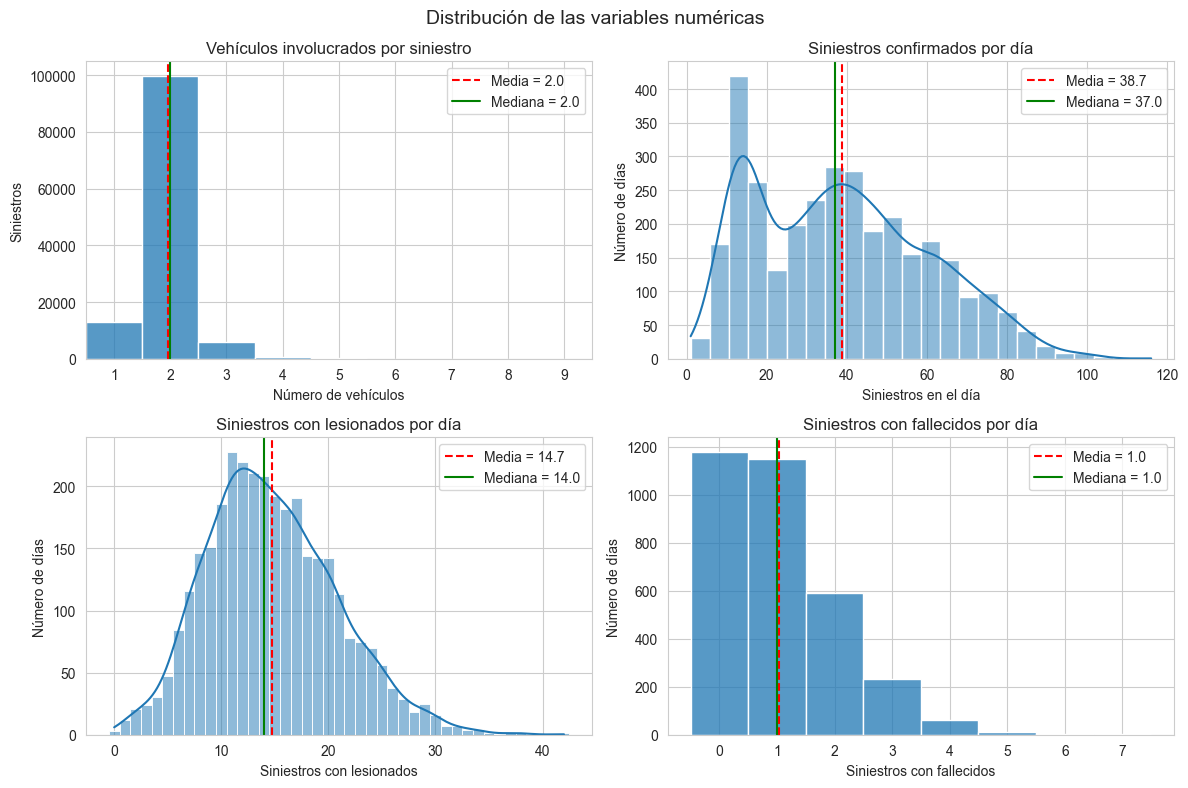

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Cada panel: histograma con líneas de media y mediana
paneles = [
    (confirmados["numero_vehiculos"].dropna(), "Vehículos involucrados por siniestro", "Número de vehículos", "Siniestros"),
    (diario["siniestros"], "Siniestros confirmados por día", "Siniestros en el día", "Número de días"),
    (diario["con_lesionado"], "Siniestros con lesionados por día", "Siniestros con lesionados", "Número de días"),
    (diario["con_fallecido"], "Siniestros con fallecidos por día", "Siniestros con fallecidos", "Número de días"),
]

for ax, (serie, titulo, eje_x, eje_y) in zip(axes.ravel(), paneles):
    # En los conteos pequeños (vehículos, fallecidos) la KDE no aporta, por eso solo se usa en los otros
    sns.histplot(serie, discrete=(serie.max() < 50), kde=(serie.max() > 20), ax=ax)
    ax.axvline(serie.mean(), color="red", linestyle="--", label=f"Media = {serie.mean():.1f}")
    ax.axvline(serie.median(), color="green", linestyle="-", label=f"Mediana = {serie.median():.1f}")
    ax.set_title(titulo)
    ax.set_xlabel(eje_x)
    ax.set_ylabel(eje_y)
    ax.legend()

axes[0, 0].set_xlim(0.5, 9.5)
fig.suptitle("Distribución de las variables numéricas", fontsize=14)
plt.tight_layout()
plt.savefig(RUTA_GRAFICAS / "fa_02_histogramas.png")
plt.show()

**Insight:** el siniestro típico involucra 2 vehículos; los de 4 o más son raros. Los siniestros diarios tienen una distribución bimodal (un pico cerca de 13 y otro cerca de 40), lo que indica que en el periodo hay dos regímenes de registro distintos y no un comportamiento homogéneo. Los siniestros con fallecido son eventos de conteo bajo (0 a 2 por día la mayoría de las veces) con asimetría positiva (1,06) y cola a la derecha: hay días puntuales con 5 a 7 siniestros fatales. `numero_vehiculos` tiene una curtosis muy alta (12,3) porque casi todos los valores son 2.

## 5. Boxplots para detectar valores atípicos

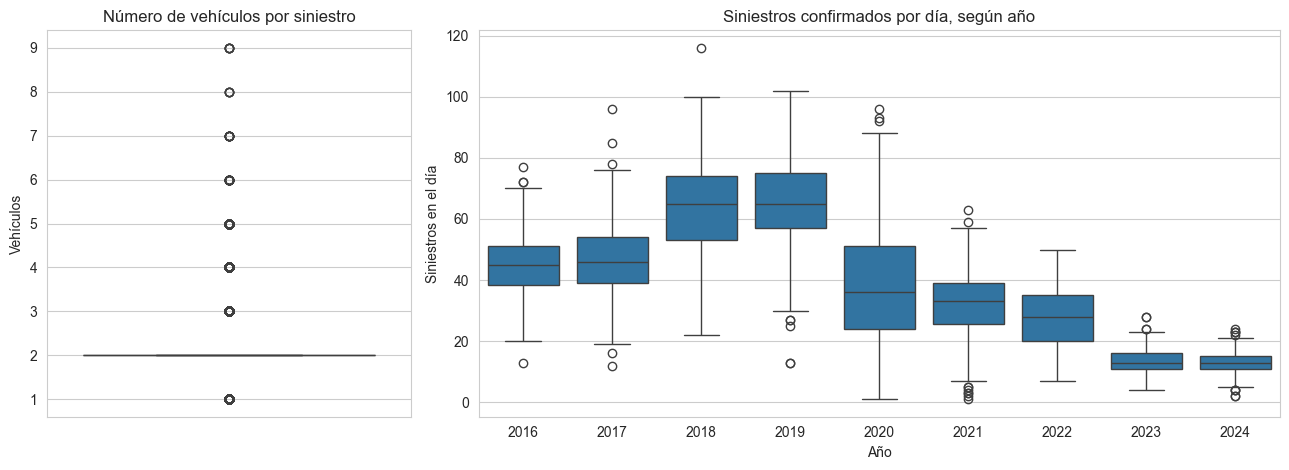

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 2.2]})

sns.boxplot(y=confirmados["numero_vehiculos"], ax=axes[0])
axes[0].set_title("Número de vehículos por siniestro")
axes[0].set_ylabel("Vehículos")

sns.boxplot(data=diario, x="anio", y="siniestros", ax=axes[1])
axes[1].set_title("Siniestros confirmados por día, según año")
axes[1].set_xlabel("Año")
axes[1].set_ylabel("Siniestros en el día")

plt.tight_layout()
plt.savefig(RUTA_GRAFICAS / "fa_03_boxplots.png")
plt.show()

In [11]:
# Cuantificación de atípicos con IQR (solo diagnóstico; el tratamiento se decide en la Fase B)
for nombre, serie in [("numero_vehiculos", confirmados["numero_vehiculos"].dropna()),
                      ("siniestros por dia", diario["siniestros"])]:
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    atipicos = ((serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)).sum()
    print(f"{nombre}: Q1={q1}, Q3={q3}, IQR={iqr} -> {atipicos:,} atípicos ({atipicos / len(serie):.1%})")

print("Máximo de vehículos en un siniestro confirmado:", confirmados["numero_vehiculos"].max())

numero_vehiculos: Q1=2.0, Q3=2.0, IQR=0.0 -> 19,604 atípicos (16.4%)
siniestros por dia: Q1=18.0, Q3=54.0, IQR=36.0 -> 1 atípicos (0.0%)
Máximo de vehículos en un siniestro confirmado: 9


**Insight:** como casi todos los siniestros tienen exactamente 2 vehículos, el IQR vale 0 y la regla marca como "atípico" todo lo que no sea 2 (unos 19.600 casos, incluidos los de 1 vehículo). Eso muestra que el IQR no sirve para una variable discreta tan concentrada: los choques múltiples (hasta 9 vehículos) son eventos reales y se deben conservar. En la serie diaria, el nivel cae a la mitad desde 2020: más que atípicos, hay un cambio estructural (pandemia y cambio en la forma de registrar) que hay que tener en cuenta al modelar.

## 6. Heatmap de correlación (Pearson y Spearman)

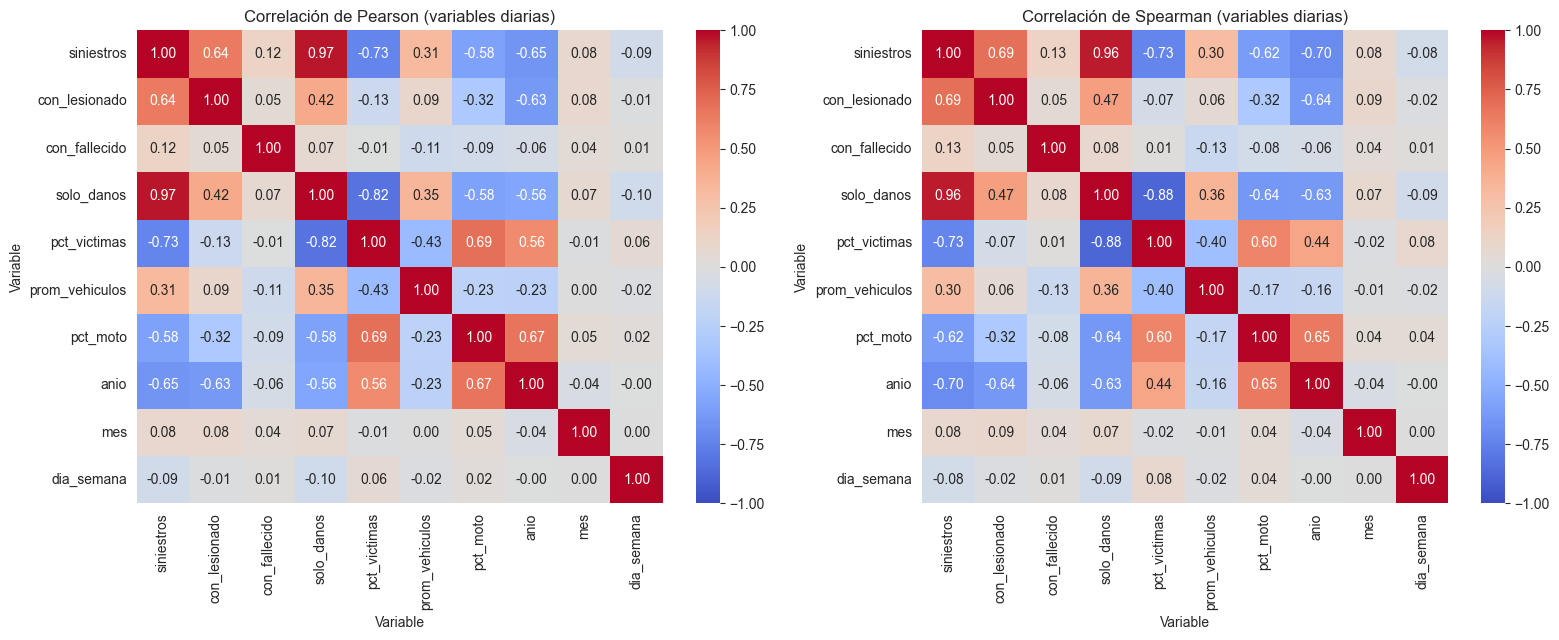

In [12]:
variables_corr = ["siniestros", "con_lesionado", "con_fallecido", "solo_danos",
                  "pct_victimas", "prom_vehiculos", "pct_moto", "anio", "mes", "dia_semana"]

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

sns.heatmap(diario[variables_corr].corr(method="pearson"), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Correlación de Pearson (variables diarias)")
axes[0].set_xlabel("Variable")
axes[0].set_ylabel("Variable")

sns.heatmap(diario[variables_corr].corr(method="spearman"), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Correlación de Spearman (variables diarias)")
axes[1].set_xlabel("Variable")
axes[1].set_ylabel("Variable")

plt.tight_layout()
plt.savefig(RUTA_GRAFICAS / "fa_04_heatmap_correlacion.png")
plt.show()

**Insight:** el volumen diario de siniestros lo explican casi por completo los de solo daños (r = 0,97), mientras que los siniestros con fallecido casi no se relacionan con el volumen (r = 0,12): **los días con más choques no son los días con más muertes**. La fuerte relación entre `pct_moto` y `pct_victimas` (0,69) está en parte inflada por el año (ambas suben a medida que desaparecen los registros de solo daños), así que hay que confirmarla siniestro por siniestro (sección 7.2). Pearson y Spearman dan valores parecidos, así que las relaciones no dependen de unos pocos días extremos.

## 7. Gráficos adicionales

### 7.1 Evolución mensual por gravedad (líneas)

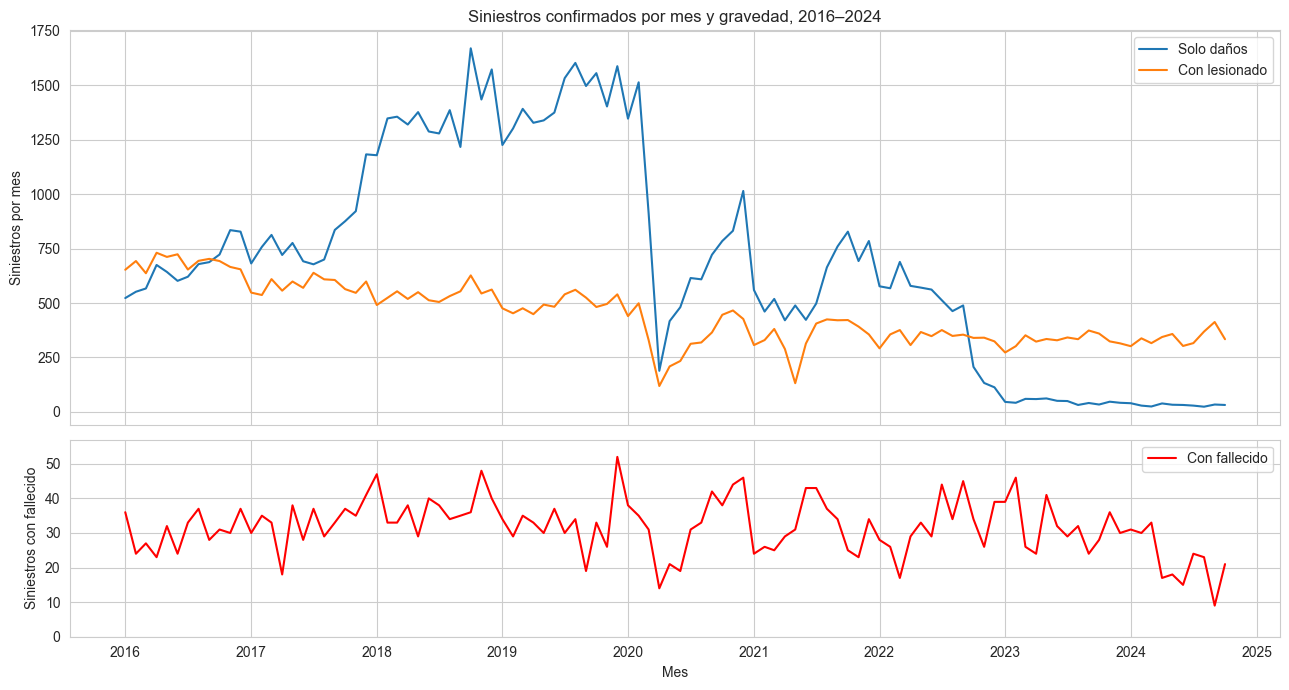

gravedad,Solo daños,Con lesionado,Con fallecido
anio,,,
2016.0,7936,8215,362
2017.0,9637,6985,394
2018.0,16428,6475,451
2019.0,17142,5974,392
2020.0,9438,4167,392
2021.0,7101,4175,374
2022.0,5464,4131,384
2023.0,566,3963,387
2024.0,318,3415,224


In [13]:
# Conteo mensual por gravedad (se excluye noviembre de 2024: solo tiene 2 días de datos)
mensual = (
    confirmados.groupby([confirmados["fecha"].dt.strftime("%Y-%m"), "gravedad"])
    .size()
    .unstack()
    .fillna(0)
)
mensual = mensual[mensual.index < "2024-11"]
mensual.index = pd.to_datetime(mensual.index)

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})

axes[0].plot(mensual.index, mensual["Solo daños"], label="Solo daños")
axes[0].plot(mensual.index, mensual["Con lesionado"], label="Con lesionado")
axes[0].set_title("Siniestros confirmados por mes y gravedad, 2016–2024")
axes[0].set_ylabel("Siniestros por mes")
axes[0].legend()

# Los fallecidos van en un panel aparte porque su escala es mucho menor
axes[1].plot(mensual.index, mensual["Con fallecido"], color="red", label="Con fallecido")
axes[1].set_ylabel("Siniestros con fallecido")
axes[1].set_xlabel("Mes")
axes[1].set_ylim(0, mensual["Con fallecido"].max() + 5)
axes[1].legend()

plt.tight_layout()
plt.savefig(RUTA_GRAFICAS / "fa_05_tendencia_mensual.png")
plt.show()

display(confirmados.groupby("anio")["gravedad"].value_counts().unstack()[ORDEN_GRAVEDAD[1:]])

**Insight:** los registros de solo daños se desploman desde finales de 2022 y casi desaparecen en 2023, lo que coincide con la Ley 2251 de 2022, que permite a los conductores arreglar choques simples sin intervención de un agente. En cambio, los siniestros con fallecido se mantienen estables en unos 380 por año entre 2016 y 2023 (2024 está incompleto). La mortalidad vial **no ha bajado**, aunque el total de registros sí. La caída de abril de 2020 corresponde a la cuarentena por COVID-19.

### 7.2 Gravedad según participación de motocicletas (barras)

,es_lesionado,es_fallecido
Sin motocicleta,22.9,2.8
Con motocicleta,65.0,2.6


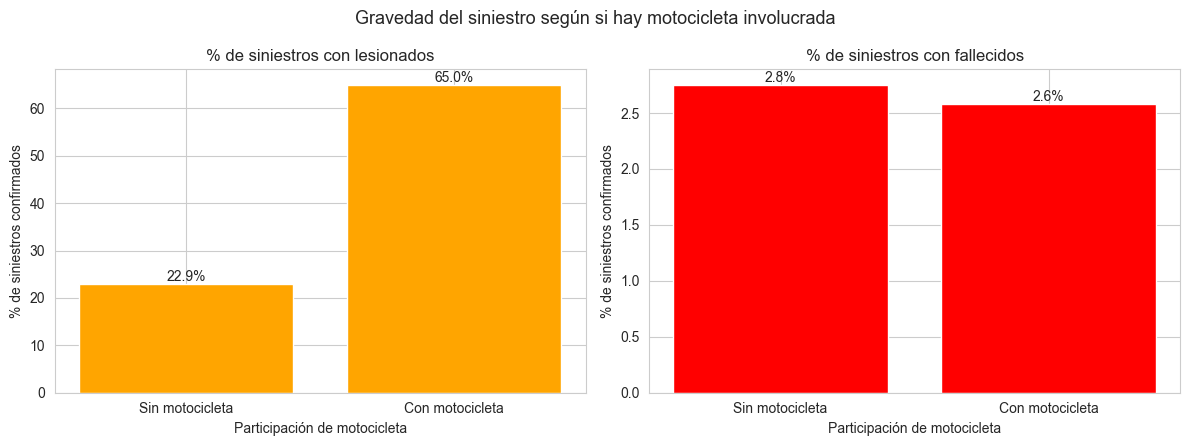

In [14]:
# % de siniestros con lesionado y con fallecido, con y sin motocicleta
tabla_moto = confirmados.groupby("involucra_moto")[["es_lesionado", "es_fallecido"]].mean() * 100
tabla_moto.index = ["Sin motocicleta", "Con motocicleta"]
display(tabla_moto.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, columna, titulo, color in [
    (axes[0], "es_lesionado", "% de siniestros con lesionados", "orange"),
    (axes[1], "es_fallecido", "% de siniestros con fallecidos", "red"),
]:
    ax.bar(tabla_moto.index, tabla_moto[columna], color=color)
    for x, valor in enumerate(tabla_moto[columna]):
        ax.text(x, valor, f"{valor:.1f}%", ha="center", va="bottom")
    ax.set_title(titulo)
    ax.set_xlabel("Participación de motocicleta")
    ax.set_ylabel("% de siniestros confirmados")

fig.suptitle("Gravedad del siniestro según si hay motocicleta involucrada", fontsize=13)
plt.tight_layout()
plt.savefig(RUTA_GRAFICAS / "fa_06_gravedad_moto.png")
plt.show()

**Insight:** cuando hay una motocicleta involucrada, el 65% de los siniestros deja lesionados, frente a un 23% cuando no la hay: el riesgo de lesión casi se triplica. El porcentaje de fallecidos es parecido en ambos grupos (cerca del 2,7%). Esto convierte al motociclista en el actor prioritario para campañas y controles, y señala `involucra_moto` como una de las variables más prometedoras para el modelo de la Fase C.

### 7.3 Siniestros diarios y gravedad por día de la semana (violín + barras)

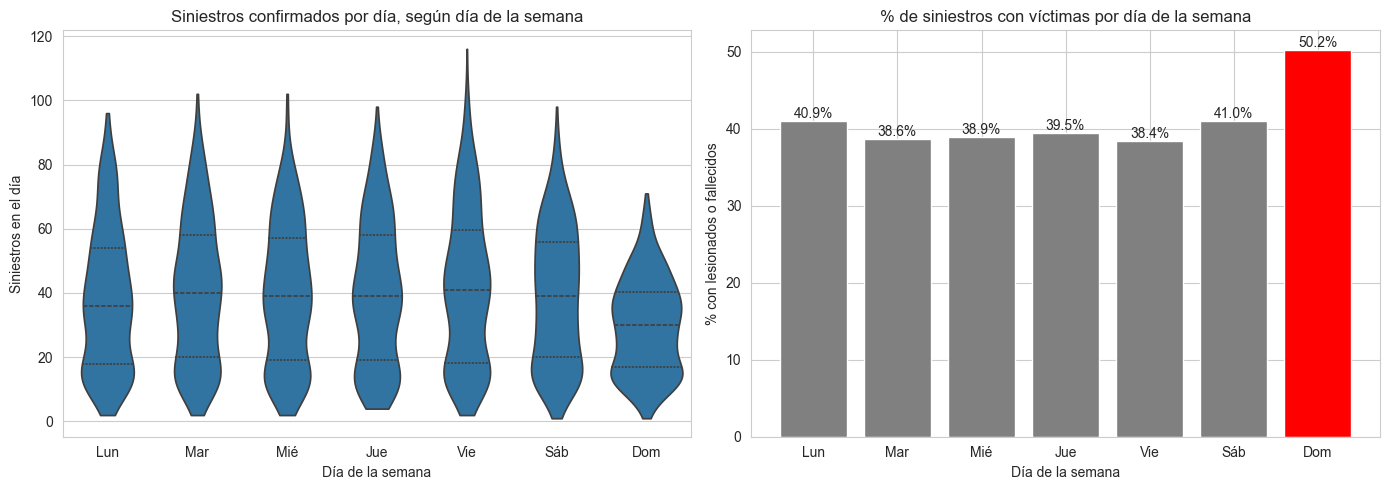

,% con fallecido
Lun,3.0
Mar,2.6
Mié,2.4
Jue,2.2
Vie,2.3
Sáb,2.8
Dom,4.0


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.violinplot(data=diario, x="dia_semana", y="siniestros", inner="quartile", cut=0, ax=axes[0])
axes[0].set_xticks(range(7))
axes[0].set_xticklabels(DIAS)
axes[0].set_title("Siniestros confirmados por día, según día de la semana")
axes[0].set_xlabel("Día de la semana")
axes[0].set_ylabel("Siniestros en el día")

victimas_dia = confirmados.groupby("dia_semana")["con_victimas"].mean() * 100
colores = ["gray"] * 6 + ["red"]
axes[1].bar(DIAS, victimas_dia, color=colores)
for x, valor in enumerate(victimas_dia):
    axes[1].text(x, valor, f"{valor:.1f}%", ha="center", va="bottom")
axes[1].set_title("% de siniestros con víctimas por día de la semana")
axes[1].set_xlabel("Día de la semana")
axes[1].set_ylabel("% con lesionados o fallecidos")

plt.tight_layout()
plt.savefig(RUTA_GRAFICAS / "fa_07_dia_semana.png")
plt.show()

fallecidos_dia = confirmados.groupby("dia_semana")["es_fallecido"].mean() * 100
fallecidos_dia.index = DIAS
display(fallecidos_dia.round(1).to_frame("% con fallecido"))

**Insight:** el domingo es el día con **menos** siniestros (unos 30 diarios frente a unos 40 entre semana), pero también el más grave: la mitad deja víctimas y la proporción con fallecidos sube a cerca del 4%, frente a un 2,2–3% entre semana. Menos tráfico con más velocidad y posible consumo de alcohol es una hipótesis que justifica operativos específicos de fin de semana.

### 7.4 Pareto de tipos de vehículo implicados

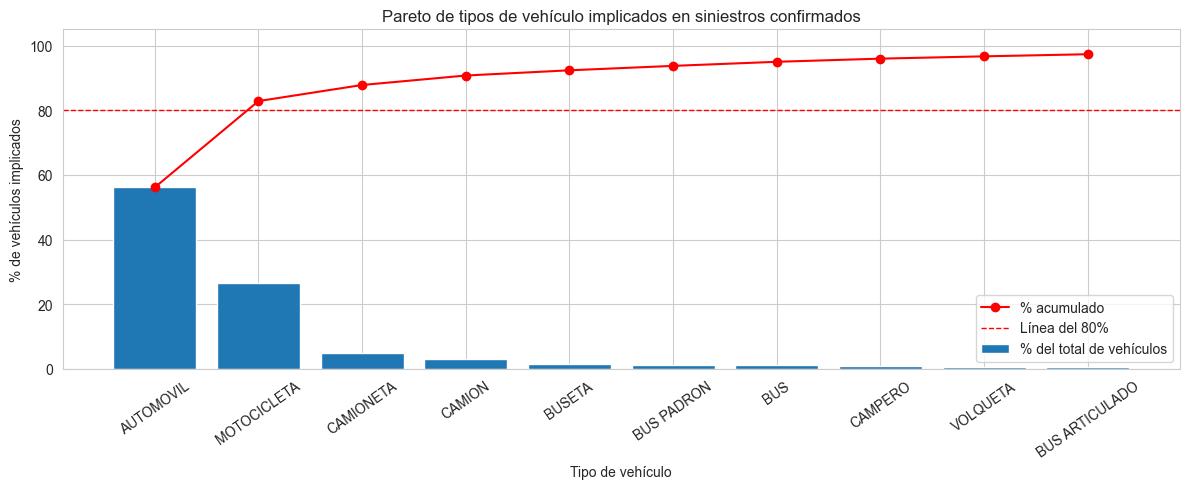

,%,% acumulado
tipos_vehiculos,,
AUTOMOVIL,56.1,56.1
MOTOCICLETA,26.7,82.8
CAMIONETA,5.0,87.8
CAMION,2.9,90.7
BUSETA,1.6,92.4
BUS PADRON,1.4,93.7
BUS,1.3,95.0
CAMPERO,1.0,96.0
VOLQUETA,0.7,96.7


In [16]:
# Cada siniestro puede tener varios vehículos separados por coma
vehiculos = (
    confirmados["tipos_vehiculos"].dropna().str.upper().str.split(",")
    .explode().str.strip().str.replace('"', "", regex=False)
)
porcentaje = vehiculos.value_counts(normalize=True) * 100
top = porcentaje.head(10)
acumulado = top.cumsum()

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(top.index, top, label="% del total de vehículos")
ax.plot(top.index, acumulado, color="red", marker="o", label="% acumulado")
ax.axhline(80, color="red", linestyle="--", linewidth=1, label="Línea del 80%")
ax.set_title("Pareto de tipos de vehículo implicados en siniestros confirmados")
ax.set_xlabel("Tipo de vehículo")
ax.set_ylabel("% de vehículos implicados")
ax.set_ylim(0, 105)
ax.tick_params(axis="x", rotation=35)
ax.legend()
plt.tight_layout()
plt.savefig(RUTA_GRAFICAS / "fa_08_pareto_vehiculos.png")
plt.show()

display(pd.DataFrame({"%": top.round(1), "% acumulado": acumulado.round(1)}))

**Insight:** solo dos tipos de vehículo, automóviles (56%) y motocicletas (27%), suman el 83% de todos los vehículos implicados en siniestros confirmados; al agregar camionetas y camiones se supera el 90%. Una estrategia de prevención centrada en autos y motos cubre la mayor parte del problema.

### 7.5 Gravedad por tipo de accidente (2021 en adelante)

tipo_accidente
CHOQUE               17296
ATROPELLO             2157
VOLCAMIENTO            655
CAIDA DE OCUPANTE      514
Name: count, dtype: int64[pyarrow]


,con_victimas,es_fallecido
tipo_accidente,,
CHOQUE,54.4,2.1
VOLCAMIENTO,84.1,11.1
ATROPELLO,92.7,8.0
CAIDA DE OCUPANTE,95.9,0.4


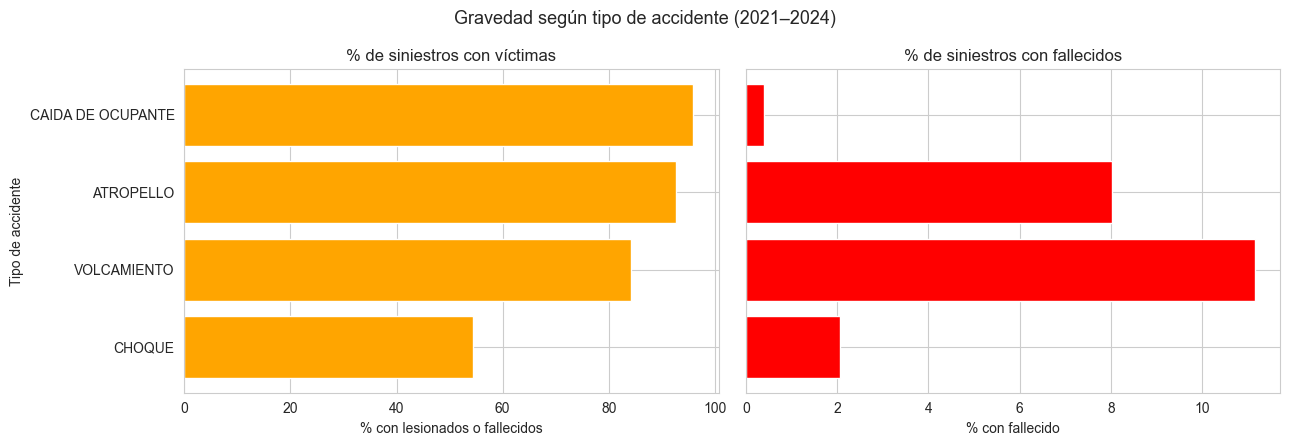

In [17]:
# Solo desde 2021 el tipo de accidente se registra de forma consistente (ver sección 3)
recientes = confirmados[(confirmados["anio"] >= 2021) & confirmados["tipo_accidente"].notna()].copy()
recientes["tipo_accidente"] = recientes["tipo_accidente"].replace({"CAIDA OCUPANTE": "CAIDA DE OCUPANTE"})
recientes = recientes[recientes["tipo_accidente"].isin(["CHOQUE", "ATROPELLO", "VOLCAMIENTO", "CAIDA DE OCUPANTE"])]
print(recientes["tipo_accidente"].value_counts())

tabla_tipo = recientes.groupby("tipo_accidente")[["con_victimas", "es_fallecido"]].mean() * 100
tabla_tipo = tabla_tipo.sort_values("con_victimas")
display(tabla_tipo.round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
axes[0].barh(tabla_tipo.index, tabla_tipo["con_victimas"], color="orange")
axes[0].set_title("% de siniestros con víctimas")
axes[0].set_xlabel("% con lesionados o fallecidos")
axes[0].set_ylabel("Tipo de accidente")

axes[1].barh(tabla_tipo.index, tabla_tipo["es_fallecido"], color="red")
axes[1].set_title("% de siniestros con fallecidos")
axes[1].set_xlabel("% con fallecido")

fig.suptitle("Gravedad según tipo de accidente (2021–2024)", fontsize=13)
plt.tight_layout()
plt.savefig(RUTA_GRAFICAS / "fa_09_gravedad_tipo_accidente.png")
plt.show()

**Insight:** el choque es el tipo más frecuente (unos 17.300 casos desde 2021), pero casi la mitad son solo daños y apenas un 2% deja fallecidos. Los atropellos (8% con fallecido) y los volcamientos (11%) son entre 4 y 5 veces más letales, y más del 84% de ellos deja víctimas. Esto apunta a la protección del peatón y al control de velocidad como prioridades.

## 8. Conclusiones de la Fase A

1. **La mortalidad vial no baja aunque bajen los registros.** El total de siniestros registrados cae a menos de la mitad entre 2016 y 2024, sobre todo por los de solo daños (cambio de registro y Ley 2251 de 2022), pero los siniestros con fallecido se mantienen en unos 380 por año (2016–2023).
2. **La motocicleta casi triplica el riesgo de lesión** (65% frente a 23% de siniestros con lesionados), y los atropellos y volcamientos son 4 a 5 veces más letales que los choques.
3. **El domingo tiene menos siniestros pero más graves:** la mitad deja víctimas y la proporción de fallecidos es la más alta de la semana.

**Implicaciones para las siguientes fases**
- Fase B: la completitud depende del año (`medio_reporte` y `tipo_accidente` casi vacíos antes de 2021), así que la estrategia de imputación debe considerar el periodo; el IQR no es adecuado para `numero_vehiculos`.
- Fase C: la variable objetivo propuesta es `con_victimas` (clasificación binaria sobre siniestros confirmados), con predictores como `involucra_moto`, `dia_semana`, `numero_vehiculos`, `mes`, `anio` y `tipo_accidente`.